<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/Valutazione_sul_Test_Set_e_Interpretabilit%C3%A0_(SHAP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5. Modello Finale, Valutazione sul Test Set e Interpretabilità (SHAP)

In quest'ultima fase, l'analisi abbandona la Cross-Validation per approdare alla valutazione definitiva e all'interpretabilità. I passaggi metodologici sono tre:

1. **Tuning degli Iperparametri:** Ottimizzazione del parametro di regolarizzazione inversa `C` della Regressione Logistica (il modello selezionato per le sue performance paritetiche e la natura lineare) sull'intero Train Set a N=40.
2. **Valutazione Finale (Hold-out Test Set):** Il modello ottimizzato viene esposto per la prima e unica volta al Test Set (il 20% dei dati segregati all'inizio dello studio) per certificare le sue reali capacità di generalizzazione.
3. **Interpretabilità (SHAP):** Apertura della "scatola nera" tramite i valori di Shapley (SHAP) per quantificare l'impatto globale e locale delle feature posizionali.

In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import warnings
warnings.filterwarnings('ignore')

# 1. CARICAMENTO DATI E PREPARAZIONE
df_train = pd.read_csv('train_features_N40.csv').dropna()
df_test = pd.read_csv('test_features_N40.csv').dropna()

if 'rating_diff' not in df_train.columns:
    df_train['rating_diff'] = df_train['white_rating'] - df_train['black_rating']
    df_test['rating_diff'] = df_test['white_rating'] - df_test['black_rating']

# Rimuovo solo l'ID della partita (che non serve per prevedere) e separo il Target
colonne_escluse = ['winner', 'id']
X_train = df_train.drop(columns=[c for c in colonne_escluse if c in df_train.columns])
y_train = df_train['winner']

X_test = df_test.drop(columns=[c for c in colonne_escluse if c in df_test.columns])
y_test = df_test['winner']

# Standardizzazione
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 2. TUNING DEGLI IPERPARAMETRI
print("--- RICERCA DEL PARAMETRO C IN CORSO... ---")
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

modello_finale = grid.best_estimator_
print(f"Miglior parametro trovato: C = {grid.best_params_['C']}")
print(f"ROC-AUC atteso (da CV): {grid.best_score_:.3f}\n")

# 3. VALUTAZIONE SUL TEST SET
print("--- VALUTAZIONE SUL TEST SET UNSEEN ---")
y_pred = modello_finale.predict(X_test_scaled)
y_prob = modello_finale.predict_proba(X_test_scaled)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_prob):.3f}")
print(f"Test Log-Loss: {log_loss(y_test, y_prob):.3f}")

--- RICERCA DEL PARAMETRO C IN CORSO... ---
Miglior parametro trovato: C = 1
ROC-AUC atteso (da CV): 0.799

--- VALUTAZIONE SUL TEST SET UNSEEN ---
Test Accuracy: 71.8%
Test ROC-AUC:  0.800
Test Log-Loss: 0.540


--- GENERAZIONE GRAFICI SHAP ---


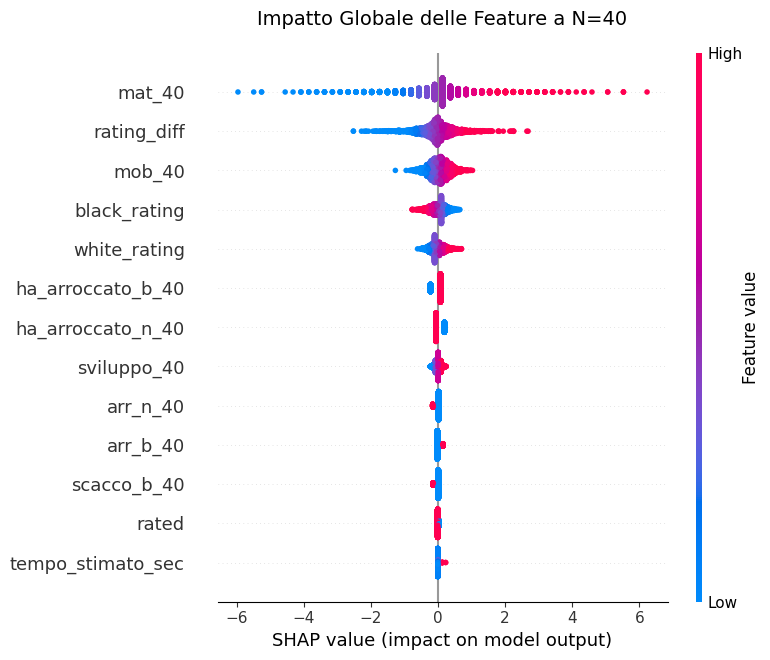

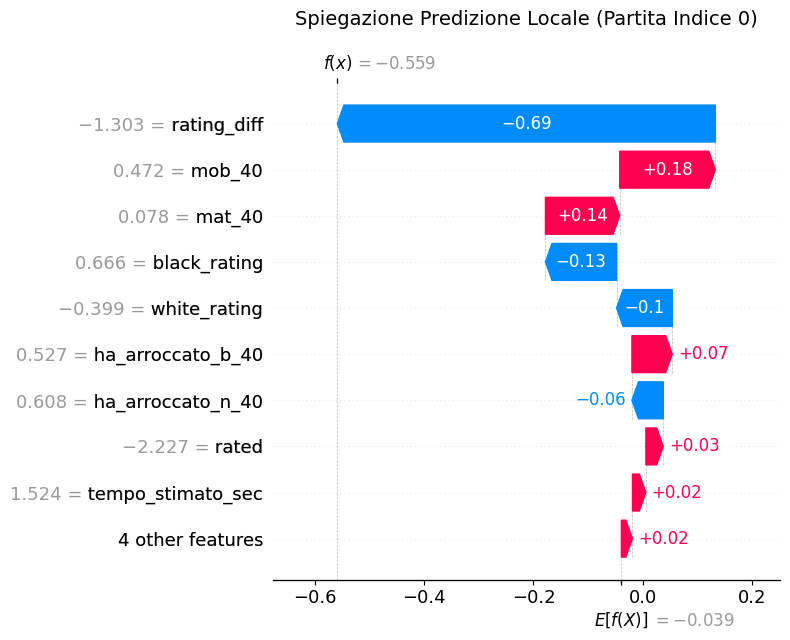

In [3]:
import shap
import matplotlib.pyplot as plt

print("--- GENERAZIONE GRAFICI SHAP ---")

# Inizializza l'Explainer lineare (ottimizzato per la Regressione Logistica)
explainer = shap.LinearExplainer(modello_finale, X_train_scaled)
shap_values = explainer(X_test_scaled)

# Grafico 1: L'Importanza Globale (Summary Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_scaled, show=False)
plt.title("Impatto Globale delle Feature a N=40", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# Grafico 2: La spiegazione di una partita locale (Waterfall Plot)
indice_partita = 0 # Radiografia della prima partita del Test Set
base_value = explainer.expected_value

plt.figure(figsize=(8, 5))
shap.waterfall_plot(shap.Explanation(values=shap_values.values[indice_partita],
                                     base_values=base_value,
                                     data=X_test_scaled.iloc[indice_partita],
                                     feature_names=X_test_scaled.columns), show=False)
plt.title(f"Spiegazione Predizione Locale (Partita Indice {indice_partita})", fontsize=14, pad=20)
plt.tight_layout()
plt.show()